<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB/Experiment%202%3A%20Covariance%2C%20Eigenvalues%20and%20Eigenvectors%20Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

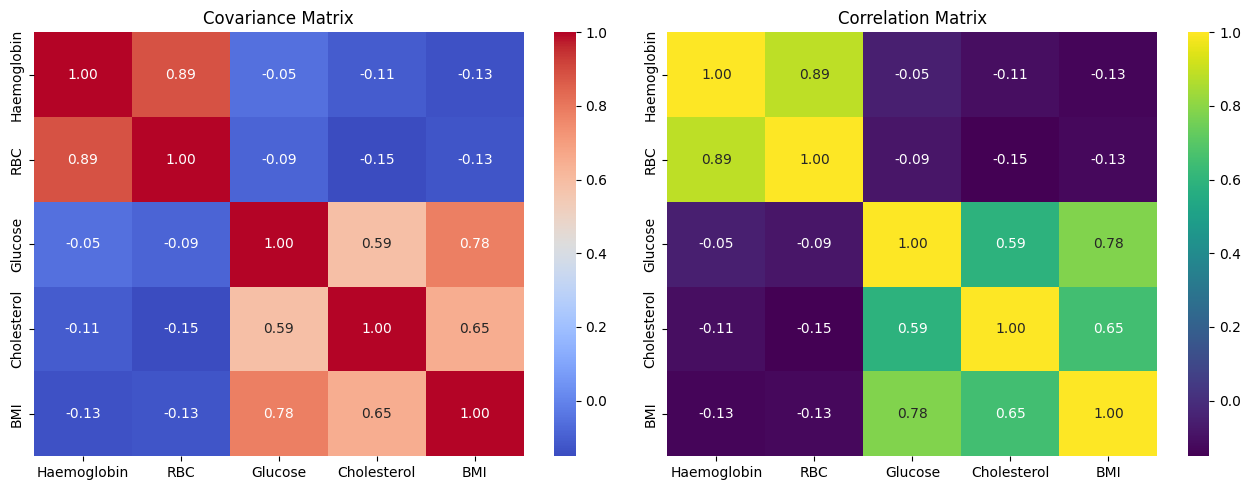

PC1: Eigenvalue = 2.4752 | Variance = 49.50%
PC2: Eigenvalue = 1.7656 | Variance = 35.31%
PC3: Eigenvalue = 0.4356 | Variance = 8.71%
PC4: Eigenvalue = 0.2156 | Variance = 4.31%
PC5: Eigenvalue = 0.1080 | Variance = 2.16%


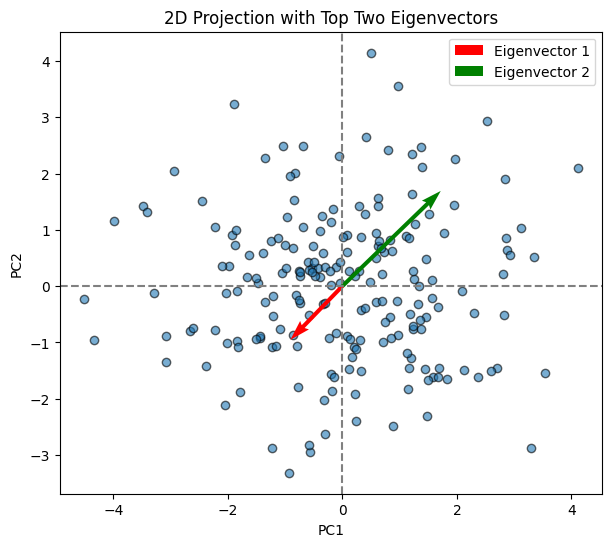

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

n = 200
hb = np.random.normal(14, 1.5, n)
rbc = 0.32 * hb + np.random.normal(0.2, 0.25, n)
bmi = np.random.normal(25, 4, n)
glucose = 3.5 * bmi + np.random.normal(15, 12, n)
chol = 4.0 * bmi + np.random.normal(80, 20, n)

df = pd.DataFrame({'Haemoglobin': hb, 'RBC': rbc, 'Glucose': glucose, 'Cholesterol': chol, 'BMI': bmi})
df_std = (df - df.mean()) / df.std()

cov_mat = np.cov(df_std.T)
corr_mat = df_std.corr()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cov_mat, annot=True, fmt=".2f", cmap="coolwarm", xticklabels=df.columns, yticklabels=df.columns, ax=axes[0])
axes[0].set_title("Covariance Matrix")
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="viridis", xticklabels=df.columns, yticklabels=df.columns, ax=axes[1])
axes[1].set_title("Correlation Matrix")
plt.tight_layout()
plt.show()

eig_vals, eig_vecs = np.linalg.eigh(cov_mat)
idx = np.argsort(eig_vals)[::-1]
eig_vals = eig_vals[idx]
eig_vecs = eig_vecs[:, idx]

var_pct = (eig_vals / np.sum(eig_vals)) * 100
for k, (val, pct) in enumerate(zip(eig_vals, var_pct), 1):
    print(f"PC{k}: Eigenvalue = {val:.4f} | Variance = {pct:.2f}%")

proj = df_std.values @ eig_vecs[:, :2]
plt.figure(figsize=(7, 6))
plt.scatter(proj[:, 0], proj[:, 1], alpha=0.6, edgecolors='k')
for i in range(2):
    vec = eig_vecs[:2, i] * np.sqrt(eig_vals[i]) * 2
    plt.quiver(0, 0, vec[0], vec[1], angles='xy', scale_units='xy', scale=1, color=['r', 'g'][i], label=f'Eigenvector {i+1}')
plt.axhline(0, color='gray', linestyle='--')
plt.axvline(0, color='gray', linestyle='--')
plt.title("2D Projection with Top Two Eigenvectors")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()